In [84]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [85]:
df = pd.read_csv("./day.csv")
df.head(10)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
5,6,2011-01-06,1,0,1,0,4,1,1,0.204348,0.233209,0.518261,0.089565,88,1518,1606
6,7,2011-01-07,1,0,1,0,5,1,2,0.196522,0.208839,0.498696,0.168726,148,1362,1510
7,8,2011-01-08,1,0,1,0,6,0,2,0.165000,0.162254,0.535833,0.266804,68,891,959
8,9,2011-01-09,1,0,1,0,0,0,1,0.138333,0.116175,0.434167,0.361950,54,768,822
9,10,2011-01-10,1,0,1,0,1,1,1,0.150833,0.150888,0.482917,0.223267,41,1280,1321


dteday - date of sharing

season - 1: winter, 2: spring, 3: summer, 4: fall

yr - 0: 2011, 1: 2012

mnth - month from 1 to 12

holiday - 1: holidays

weekday - from 0 to 6

workingday - 1: weekday, 0: weekend or holiday

weathersit - 1: clear, few clouds, partly cloudy, 2: mist, mist + cloudy, 3:	light snow, light rain, 4: heavy rain, snow + fog

temp - normalized temperature in Celsius

atemp - normalized feeling temperature

hum - normalized humidity

windspeed - normalized wind speed

casual - count of casual users

registered - count of registered users

cnt - count of total rental bikes ( casual + registered)

In [86]:
print(f"Size: {df.shape}")
print(f"Columns and data types:\n{df.dtypes}")

Size: (731, 16)
Columns and data types:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


In [87]:
temp = df['temp']

check = (df["casual"] + df['registered'] == df['cnt']).all()
print(f"Check if cnt has no mistake: {check}")

# for x,y,z in zip(casual,registered,cnt):
#     if x + y != z:
#         print(f"Cnt mistake:\nx:{x}, y:{y}, z:{z}")

df['temp_in_C'] = 47 * df["temp"] - 8
# temp_in_C = []
# for x in temp:
#     in_C = (47 * x) - 8
#     temp_in_C.append(in_C)

mean_temp_C = round(df['temp_in_C'].mean(),0)

print(f"Mean of temperature in Celsius: {mean_temp_C}")
print(f"Highest 'cnt' value: {df["cnt"].max()}")


Check if cnt has no mistake: True
Mean of temperature in Celsius: 15.0
Highest 'cnt' value: 8714


#### Data filtering

In [88]:
high_demand = df.loc[:,["dteday",'season','temp','cnt']].query('cnt > 6000')

high_demand

,dteday,season,temp,cnt
184,2011-07-04,3,0.726667,6043
438,2012-03-14,1,0.572500,6312
439,2012-03-15,1,0.557500,6192
441,2012-03-17,1,0.514167,7836
443,2012-03-19,1,0.545000,6153
...,...,...,...,...
679,2012-11-10,4,0.389167,6536
680,2012-11-11,4,0.420833,6852
681,2012-11-12,4,0.485000,6269
702,2012-12-03,4,0.452500,6234


In [89]:
print(f"Count of days with high demand: {high_demand.shape[0]}")

print(f"Average number of bike rentals on days with high demand: {round(high_demand["cnt"].mean(),2)}")


Count of days with high demand: 180
Average number of bike rentals on days with high demand: 7060.08


In [90]:
# mask = df.query('temp > 0.6 & cnt > 6000')
warm_high_demand_days = df[(df['temp'] > 0.6) & (df['cnt'] > 6000)]

df_warm_and_high_demand_days = warm_high_demand_days[["temp","cnt"]]
print(f"Number of warm and high demand days: {df_warm_and_high_demand_days.shape[0]}")

Number of warm and high demand days: 105


In [91]:
warm_or_high_demand_days = df[(df["temp"] > 0.6) | (df["cnt"] > 6000)]
# with_loc = df.loc[(df["cnt"] > 6000) | (df["temp"] > 0.6),["temp","cnt"]]

df_warm_or_high_demand_days = warm_or_high_demand_days[["temp","cnt"]]
print(f"Number of warm or high demand days: {df_warm_or_high_demand_days.shape[0]}")

Number of warm or high demand days: 329


In [92]:
percentage_of_high_demand_days = high_demand.shape[0]/df.shape[0] * 100

print(f"Percentage of high demand days: {round(percentage_of_high_demand_days,2)} %")

Percentage of high demand days: 24.62 %


In [93]:
df_spring_summer_demand = df.loc[df["season"].isin([2,3]),["dteday",'season','temp','cnt']]

average_bike_rentals_spring_summer = df_spring_summer_demand["cnt"].mean()

print(f"Average number of bike rentals during spring and summer: {round(average_bike_rentals_spring_summer,2)}")


Average number of bike rentals during spring and summer: 5321.82


In [94]:
df_spring_demand = df.loc[df['season'] == 2, ["dteday",'season','temp','cnt']]
df_summer_demand = df.loc[df['season'] == 3, ["dteday",'season','temp','cnt']]

average_spring_demand = df_spring_demand["cnt"].mean()
average_summer_demand = df_summer_demand["cnt"].mean()
demand_difference = abs(round(average_spring_demand-average_summer_demand,2))

print(f"Demand in spring: {round(average_spring_demand,2)}")
print(f"Demand in summer: {round(average_summer_demand,2)}")

if average_spring_demand > average_summer_demand:
    print(f"Demand is higher in spring by about {demand_difference} rentals per day")
elif average_summer_demand > average_spring_demand:
    print(f"Demand is higher in summer by about {demand_difference} rentals per day")
else:
    print(f"Demand in spring and summer is the same: {average_spring_demand} rentals per day")


Demand in spring: 4992.33
Demand in summer: 5644.3
Demand is higher in summer by about 651.97 rentals per day


In [95]:
df_clear_partly_cloudy = df.loc[df['weathersit'] == 1,:]
df_mist_cloudy = df.loc[df['weathersit'] == 2,:]

average_rental_clear_partly_cloudy = df_clear_partly_cloudy["cnt"].mean()
average_rental_mist_cloudy = df_mist_cloudy["cnt"].mean()

percentage_difference = ((average_rental_clear_partly_cloudy - average_rental_mist_cloudy)/average_rental_mist_cloudy) * 100

print(f"Average number of bike rentals with clear or partly cloudy skies: {round(average_rental_clear_partly_cloudy,2)}")
print(f"Average number of bike rentals with mist or mist and cloudy skies: {round(average_rental_mist_cloudy,2)}")
# print(f"Difference between bike rentals during days with clear/partly clody skies and mist or/and cloudy days: {round(abs(percentage_difference),2)} %")

print(f"Bike rental is higher by about {round(percentage_difference,2)}% during days with clear or partly cloudy skies")

Average number of bike rentals with clear or partly cloudy skies: 4876.79
Average number of bike rentals with mist or mist and cloudy skies: 4035.86
Bike rental is higher by about 20.84% during days with clear or partly cloudy skies


In [96]:
# indices_cnt = np.where(df["cnt"] > 6000)
# indices_df = df.iloc[indices_cnt][["dteday","season",'temp','cnt']]
#
# print(indices_df.equals(high_demand))

In [97]:
df.dteday = pd.to_datetime(df.dteday)
df['year'] = df['dteday'].dt.year
df['month'] = df['dteday'].dt.month
df['day'] = df['dteday'].dt.day
df

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,temp_in_C,year,month,day
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,8.175849,2011,1,1
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,9.083466,2011,1,2
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,1.229108,2011,1,3
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,1.400000,2011,1,4
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,2.666979,2011,1,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114,3.945849,2012,12,27
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095,3.906651,2012,12,28
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341,3.906651,2012,12,29
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796,4.024151,2012,12,30


In [98]:
monthly_demand = df.groupby(['year','month'])['cnt'].mean().reset_index(name = "avg_daily_rentals")
monthly_demand['avg_daily_rentals'] = round(monthly_demand['avg_daily_rentals'],2)
monthly_demand

,year,month,avg_daily_rentals
0,2011,1,1231.90
1,2011,2,1721.96
2,2011,3,2065.97
3,2011,4,3162.33
4,2011,5,4381.32
5,2011,6,4783.73
6,2011,7,4559.39
7,2011,8,4409.39
8,2011,9,4247.27
9,2011,10,3984.23


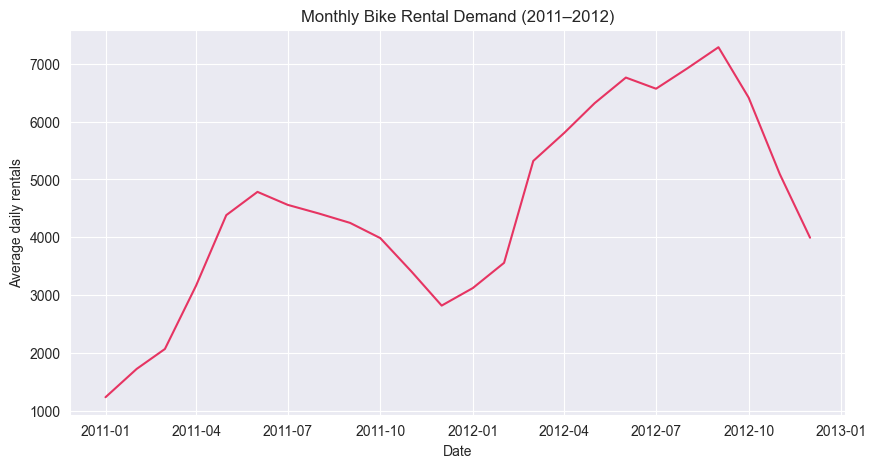

In [99]:
monthly_demand['date'] = pd.to_datetime(dict(
    year=monthly_demand['year'],
    month=monthly_demand['month'],
    day=1
))

plt.figure(figsize = (10,5))
plt.plot(monthly_demand['date'], monthly_demand['avg_daily_rentals'],color='#E63462')
plt.xlabel('Date')
plt.ylabel('Average daily rentals')
plt.title('Monthly Bike Rental Demand (2011–2012)')
plt.show()




In [100]:
month_by_month = monthly_demand.pivot(index = "month", columns = "year", values = "avg_daily_rentals")
month_by_month['growth[%]'] = round(((month_by_month[2012] - month_by_month[2011]) / month_by_month[2011] * 100),2)
month_by_month

year,2011,2012,growth[%]
month,,,
1,1231.90,3120.77,153.33
2,1721.96,3556.45,106.53
3,2065.97,5318.55,157.44
4,3162.33,5807.47,83.65
5,4381.32,6318.23,44.21
6,4783.73,6761.00,41.33
7,4559.39,6567.97,44.05
8,4409.39,6919.45,56.93
9,4247.27,7285.77,71.54


Which months experienced the highest and lowest year-over-year growth in bike rental demand?

In [101]:
highest_growth = month_by_month['growth[%]'].max()
highest_growth_month = month_by_month['growth[%]'].idxmax()

lowest_growth = month_by_month['growth[%]'].min()
lowest_growth_month = month_by_month['growth[%]'].idxmin()

print(f"Highest growth was in month {highest_growth_month}: {highest_growth} %")
print(f"Lowest growth was in month {lowest_growth_month}: {lowest_growth} %")

Highest growth was in month 3: 157.44 %
Lowest growth was in month 6: 41.33 %


In [102]:
month_by_month['absolute_growth'] = round(month_by_month[2012] - month_by_month[2011],2)
highest_absolute_growth = month_by_month['absolute_growth'].max()
highest_absolute_growth_month = month_by_month['absolute_growth'].idxmax()

print(f'Highest absolute growth was in month {highest_absolute_growth_month}: {highest_absolute_growth} additional rentals per day')

Highest absolute growth was in month 3: 3252.58 additional rentals per day


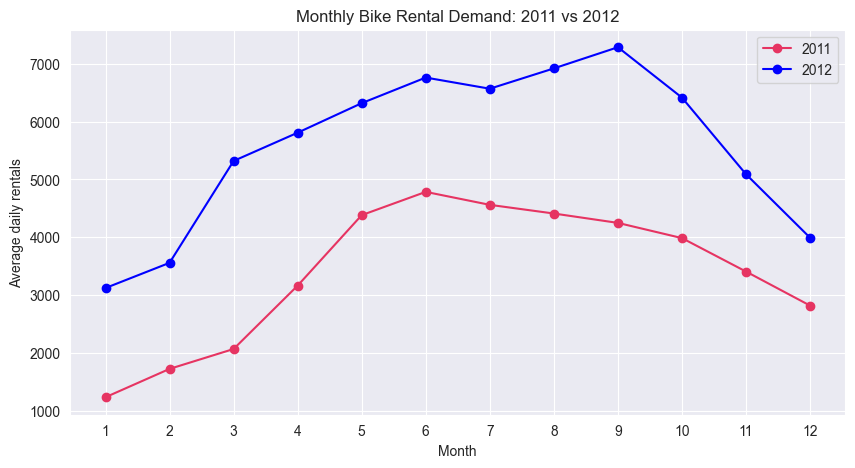

In [103]:
plt.figure(figsize=(10,5))
plt.plot(month_by_month.index, month_by_month[2011], color='#E63462',label = '2011',marker='o')
plt.plot(month_by_month.index, month_by_month[2012], color='blue', label = '2012',marker='o')
plt.xticks(range(1,13)) #to show every month
plt.xlabel('Month')
plt.ylabel('Average daily rentals')
plt.title('Monthly Bike Rental Demand: 2011 vs 2012')
plt.legend()
plt.show()

In [104]:
temp_monthly= df.groupby(['year','month'])['temp_in_C'].mean().reset_index()
temp_monthly['temp_in_C'] = round(temp_monthly['temp_in_C'],2)
temp_month_by_month = temp_monthly.pivot(index = 'month', columns = 'year', values = 'temp_in_C')
temp_month_by_month['differnce'] = temp_month_by_month[2012] - temp_month_by_month[2011]
temp_month_by_month

year,2011,2012,differnce
month,,,
1,1.29,4.93,3.64
2,5.28,6.82,1.54
3,7.59,13.12,5.53
4,14.15,14.03,-0.12
5,19.13,20.78,1.65
6,24.57,23.73,-0.84
7,27.65,27.36,-0.29
8,25.15,25.45,0.30
9,20.81,21.14,0.33


In [105]:
clear_march_2011 = df[(df['weathersit'] == 1) & (df['month'] == 3) & (df['year'] == 2011)]
clear_march_2011_count = clear_march_2011.shape[0]
print(f"Clear days in march 2011 count: {clear_march_2011_count}")

clear_march_2012_count = df.loc[:,['year','month','weathersit']].query('month == 3 and weathersit == 1 and year == 2012').shape[0]
print(f"Clear days in march 2012 count: {clear_march_2012_count}")

Clear days in march 2011 count: 17
Clear days in march 2012 count: 19
